# Inverse Discrete Fourier Transform




Any $N$ point signal, $x[i]$, can be created by adding $N/2 + 1$ cosine waves and $N/2 + 1$ sine waves. The amplitudes of the cosine and sine waves are held in the arrays $ImX[k]$ and $ReX[k]$, respectively. The synthesis equation multiplies these amplitudes by the basis functions to create a set of scaled sine and cosine waves. Adding the scaled sine and cosine waves produces the time domain signal, $x[i]$.

We can write the synthesis equation as:

$$x[i] = \displaystyle\sum_{k=0}^{N/2}{Re\bar{X}[k]\cos{(\frac{2\pi ki}{N}})} + 
\displaystyle\sum_{k=0}^{N/2}{Im\bar{X}[k]\sin{(\frac{2\pi ki}{N}})}$$

The arrays are called $Im\bar{X}[k]$ and $Re\bar{X}[k]$, rather than $ImX[k]$ and $ReX[k]$. This is because the amplitudes needed for synthesis are slightly different from the frequency domain of a signal. This is the scaling factor due to the use of an orthogonal basis decomposition. Although the conversion is only a simple normalization, it is a common bug in computer programs. Look out for it! In equation form, the conversion between the two is given by:

$$Re\bar{X}[k]= \frac{ReX[k]}{N/2}$$

$$Im\bar{X}[k]= -\frac{ImX[k]}{N/2}$$

except for two special cases:
$$Re\bar{X}[0]= \frac{ReX[0]}{N}$$

$$Re\bar{X}[N/2]= \frac{ReX[N/2]}{N}$$

Remember that $N$ is the size of the time domain signal $x[k]$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pickle

### Why the use of Scaling Factors?
To understand the use of scaling factors we can think of the frequency domain representation of a signal as a spectral density. Spectral density describes how much signal (amplitude) is present per unit of bandwidth. To convert the sinusoidal amplitudes into a spectral density, divide each amplitude by the bandwidth represented by each amplitude. To determine the bandwidth you can look at the following DFT decomposition and see that we divided each decomposition into *frequency bins*

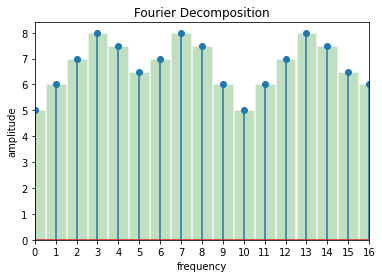

In [2]:
# Example of a frequency decomposition of a signal
t = np.arange(0,17)
dft_decomposition = np.array([5, 6, 7, 8, 7.5, 6.5, 7, 8, 7.5, 6, 5, 6, 7, 8, 7.5, 6.5, 6])

plt.stem(dft_decomposition)
plt.title('Fourier Decomposition')
plt.xlabel('frequency')
plt.ylabel('amplitude')
plt.xlim(-0.01,16.01)
plt.xticks(t);
plt.bar(t,dft_decomposition.flatten(),width=0.95, color='green', alpha=0.25, edgecolor='white');

Each frequency bin has a *width*, and in the case of samples 1 to 15 they are of *double length* than for samples 0 and 16. The length of each bin can be calculated as $2/N$ for samples 1 to 15, and $1/N$ for samples 0 and 16. (Remember that $N$ is the size of the time domain signal.) So this accounts for the scaling factor between the sinusoidal amplitudes and frequency domain, as well as the additional factor of two needed for the first and last samples.  

Why the negation of the imaginary part? This is done solely to make the real DFT consistent with our definition of DFT and later with its big brother, the complex DFT.

When dealing only with the real DFT, many authors do not include this negation. For that matter, many authors do not even include he $2/N$ scaling factor. Be prepared to find both of these missing in some discussions. They are included here for a tremendously important reason: The most efficient way to calculate the DFT is through the Fast Fourier Transform (FFT) algorithm. The FFT generates a frequency domain defined according to our previous equations. If you start messing with these normalization factors, your programs containing the FFT are not going to work as expected. 

In this Jupyter Notebook we will implement a function called `idft` which calculates the Inverse Fourier Transform of a frequency domain signal (given both real and imaginary parts.)

In this Notebook you will need to add the following fuctions to a file called `fourier.py`:
* `dft`
* `dft_magnitude`
* `arctan_correct`
* `unwrap`
* `dft_phase`
* `frequency_domain`

These function were developed in the previous excersises and will help us in this Jupyter Notebookk.

In [3]:
from fourier import dft, dft_magnitude, dft_phase, frequency_domain

In [4]:
file = {'x':'Signals/InputSignal_f32_1kHz_15kHz.dat', 'h':'Signals/Impulse_response.dat'}

x = np.loadtxt(file['x'])
N,M = x.shape
x = x.reshape(N*M, 1)

h = np.loadtxt(file['h'])
N = h.shape[0]
h = h.reshape(N, 1)

In [5]:
# Calculate the Fourier transform of x and assign it to X_rex, X_imag
# Calculate the Fourier transform of h and assign it to H_rex, H_imag
### BEGIN SOLUTION
X_rex, X_imag = dft(x)
H_rex, H_imag = dft(h)
### END SOLUTION

# Calculate the magnitude of the Fourier transform of x and assign it to X_mag
# Calculate the magnitude of the Fourier transform of h and assign it to H_mag
### BEGIN SOLUTION
X_mag = dft_magnitude(X_rex, X_imag)
H_mag = dft_magnitude(H_rex, H_imag)
### END SOLUTION

# Calculate the phase of the Fourier transform of x and assign it to X_phase
# Calculate the phase of the Fourier transform of h and assign it to H_phase
### BEGIN SOLUTION
X_phase = dft_phase(X_rex, X_imag)
H_phase = dft_phase(H_rex, H_imag)
### END SOLUTION

# Calculate the frequency domain of the Fourier transform of x and assign it to X_domain
# Calculate the frequency domain of the Fourier transform of h and assign it to H_domain
### BEGIN SOLUTION
X_domain = frequency_domain(X_mag, style='fraction')
H_domain = frequency_domain(H_mag, style='fraction')
### END SOLUTION

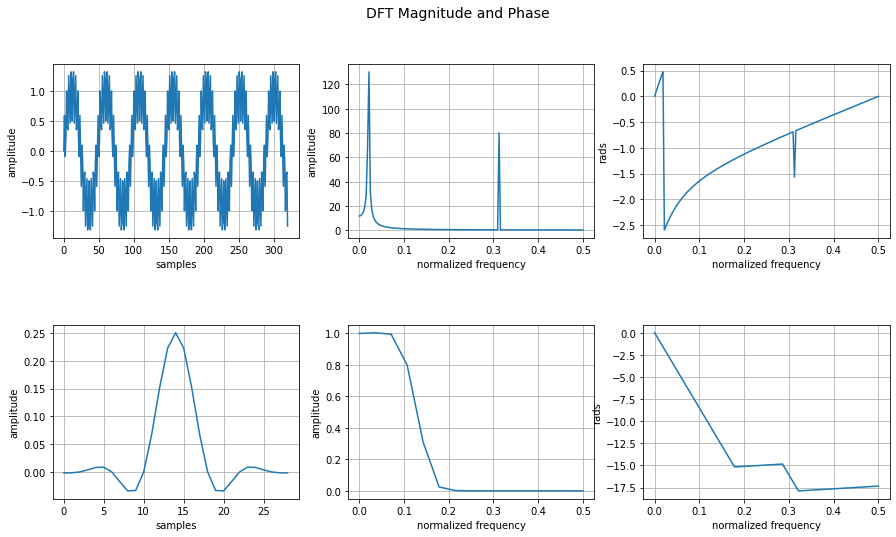

In [6]:
plt.rcParams["figure.figsize"] = (15,8)

plt.suptitle("DFT Magnitude and Phase", fontsize=14)

plt.subplot(2,3,1)
plt.plot(x)
plt.grid()
plt.xlabel('samples')
plt.ylabel('amplitude')

plt.subplot(2,3,2)
plt.plot(X_domain, X_mag)
plt.grid()
plt.xlabel('normalized frequency')
plt.ylabel('amplitude')

plt.subplot(2,3,3)
plt.plot(X_domain, X_phase)
plt.grid()
plt.xlabel('normalized frequency')
plt.ylabel('rads')

plt.subplot(2,3,4)
plt.plot(h)
plt.grid()
plt.xlabel('samples')
plt.ylabel('amplitude')

plt.subplot(2,3,5)
plt.plot(H_domain, H_mag)
plt.grid()
plt.xlabel('normalized frequency')
plt.ylabel('amplitude')

plt.subplot(2,3,6)
plt.plot(H_domain, H_phase)
plt.grid()
plt.xlabel('normalized frequency')
plt.ylabel('rads')

plt.subplots_adjust(hspace = 0.5)
plt.show()

In [7]:
with open('x_dft.pkl', 'rb') as file:
    X = pickle.load(file)

with open('h_dft.pkl', 'rb') as file:
    H = pickle.load(file)    


X_rex_pkl, X_imag_pkl = X['dft']
X_mag_pkl = X['mag']
X_phase_pkl = X['phase']
X_domain_pkl = X['domain']

assert np.isclose(X_rex, X_rex_pkl).all()
assert np.isclose(X_imag, X_imag_pkl).all()
assert np.isclose(X_phase, X_phase_pkl).all()
assert np.isclose(X_domain, X_domain_pkl).all()

H_rex_pkl, H_imag_pkl = H['dft']
H_mag_pkl = H['mag']
H_phase_pkl = H['phase']
H_domain_pkl = H['domain']

assert np.isclose(H_rex, H_rex_pkl).all()
assert np.isclose(H_imag, H_imag_pkl).all()
assert np.isclose(H_phase, H_phase_pkl).all()
assert np.isclose(H_domain, H_domain_pkl).all()

## Inverse Discrete Fourier Transform Implementation
In this part you will create two functions:

* `normalize` which calculates the normalized real and imagnary components that will be used by the `idft` function.
* `idft` which implements the synthesis equation described at the beginning of this notebook.

In [8]:
def normalize(x, part):
    """ 
    Function that calculates the normalized values of given input signal x.

    Parameters: 
    x (numpy array): Array of numbers representing the input signal to be normalized. 
    part (string): If 'real', a normalized real part is returned. If 'imag', a 
                    normalized imaginary part is returned.

    Returns: 
    numpy array: Normalized input signal x.

    """
    
    M = x.shape[0]
    N = 2*(M-1)
        
    ### BEGIN SOLUTION       
    if(part=='real'):
        norm = x/(N/2)
        norm[0] = x[0]/N
        norm[int(N/2)] = x[int(N/2)]/N
    elif(part=='imag'):
        norm = -x/(N/2)

    return norm
    ### END SOLUTION


def idft(real, imag): 
    """ 
    Function that calculates the IDFT of a signal.

    Attributes: 
    real(numpy array): Array of numbers representing the normalized real dft part of a signal.
    imag(numpy array): Array of numbers representing the normalized imaginary dft part of a signal.

    Returns: 
    numpy array: Synthetized IDFT signal, which consist of the normalized sum of cosine 
                and sine waveforms.

    """
    M = real.shape[0]
    N = 2*(M-1)
    
    real_acc = np.zeros(N)
    imag_acc = np.zeros(N)

    ### BEGIN SOLUTION
    for i in range(N):
        for k in range (M):
            real_acc[i] = real_acc[i] + real[k]*np.cos(2*np.pi*k*i/N)
            imag_acc[i] = imag_acc[i] + imag[k]*np.sin(2*np.pi*k*i/N)
    return (real_acc + imag_acc).reshape(-1,1)
    ### END SOLUTION

### Test your Inverse Implementation
You can run this test and check if your synthetized signal is the same as the output. If not, try to correct your mistakes. Remember that your `idft` function expect normalized values.

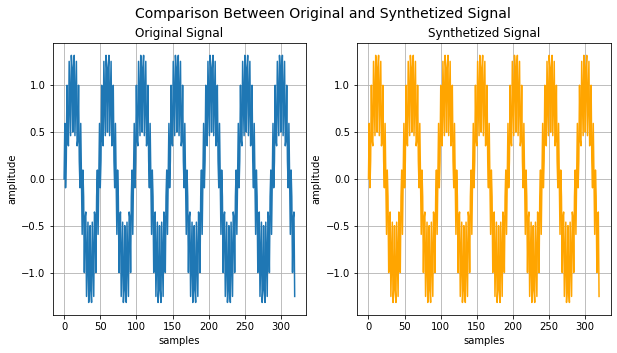

In [9]:
# Developed calculations
signal = x
real, imag = dft(signal)

norm_real = normalize(real, 'real')
norm_imag = normalize(imag, 'imag')

synth = idft(norm_real, norm_imag)


# Reference calculations
signal_fft = np.fft.fft2(x)

real_fft = np.real(signal_fft)
imag_fft = np.imag(signal_fft)

N = int(len(signal_fft)/2) + 1

assert np.isclose(real, real_fft[:N]).all()
assert np.isclose(imag, imag_fft[:N]).all()

# Plotting
plt.rcParams["figure.figsize"] = (10,5)

plt.suptitle("Comparison Between Original and Synthetized Signal", fontsize=14)

plt.subplot(1,2,1)
plt.plot(signal)
plt.xlabel('samples')
plt.ylabel('amplitude')
plt.title('Original Signal')
plt.grid()

plt.subplot(1,2,2)
plt.plot(synth, color='orange')
plt.xlabel('samples')
plt.ylabel('amplitude')
plt.title('Synthetized Signal')

plt.grid()
plt.subplots_adjust(hspace = 0.5)
plt.show()

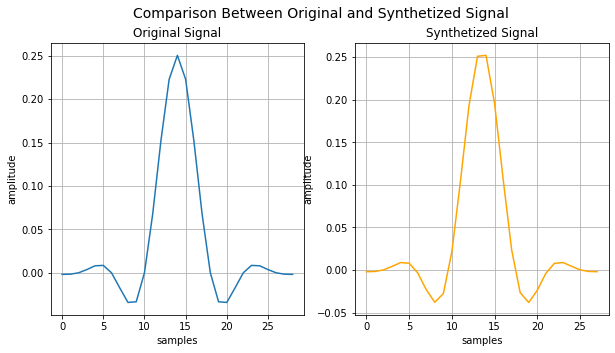

In [10]:
# Developed calculations
signal = h
real, imag = dft(signal)

norm_real = normalize(real, 'real')
norm_imag = normalize(imag, 'imag')

synth = idft(norm_real, norm_imag)


# Reference calculations
signal_fft = np.fft.fft2(h)

real_fft = np.real(signal_fft)
imag_fft = np.imag(signal_fft)

N = int(len(signal_fft)/2) + 1

assert np.isclose(real, real_fft[:N]).all()
assert np.isclose(imag, imag_fft[:N]).all()

# Plotting
plt.rcParams["figure.figsize"] = (10,5)

plt.suptitle("Comparison Between Original and Synthetized Signal", fontsize=14)

plt.subplot(1,2,1)
plt.plot(signal)
plt.xlabel('samples')
plt.ylabel('amplitude')
plt.title('Original Signal')
plt.grid()

plt.subplot(1,2,2)
plt.plot(synth, color='orange')
plt.xlabel('samples')
plt.ylabel('amplitude')
plt.title('Synthetized Signal')

plt.grid()
plt.subplots_adjust(hspace = 0.5)
plt.show()

## Signal Through a Filter
In this part, we will see how the Inverse Fourier Transform of a product of two signals in the frequency domain can lead to the same results as applying the convolution of those two signals in the time domain. To do so, **both signals must be of same size**, so you have to pad zeros to the smallest signal before doing any transformation. So before doing any calculation, create a function called `zero_padding` that tests both signals and zero pads the smallest signal.

In [11]:
def zero_padding(x, h):
    """ 
    Function that zero pads the smallest input signal.

    Attributes: 
    x(numpy array): Array of numbers representing an input signal.
    h(numpy array): Array of numbers representing an input signal.

    Returns: 
    x_pad(numpy array): Array of numbers representing an input signal x padded with zeros.
    h_pad(numpy array): Array of numbers representing an input signal h padded with zeros.
    """
    N = x.shape[0]
    M = h.shape[0]
    
    ### BEGIN SOLUTION
        
    if(M<N):
        h_pad = np.append(h,np.zeros((N-M,1)), axis=0)
        x_pad = x
    elif(M>N):
        x_pad = np.append(x,np.zeros((M-N,1)), axis=0)
        h_pad = h
    else:
        x_pad = x
        h_pad = h
        
    ### END SOLUTION
    
    return x_pad, h_pad

In [12]:
# Zero pad inputs x and h
### BEGIN SOLUTION
x_pad, h_pad = zero_padding(x, h)
### END SOLUTION

# Calculate the Fourier Transform of each signal
### BEGIN SOLUTION
real_x, imag_x = dft(x_pad)
real_h, imag_h = dft(h_pad)
### END SOLUTION

# Multiply both frequency domain signals
### BEGIN SOLUTION
G_rex = real_h*real_x
G_imx = imag_h*imag_x
### END SOLUTION

# Calculate the Inverse Fourier Transform
### BEGIN SOLUTION
G_rex_normalized = normalize(G_rex, 'real')
G_imx_normalized = normalize(G_imx, 'imag')
synthetized_signal = idft(G_rex_normalized, G_imx_normalized)
### END SOLUTION

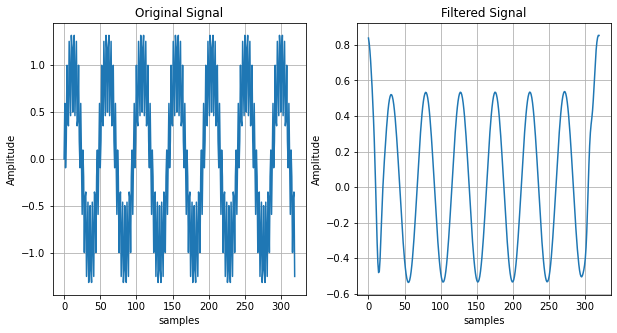

In [13]:
plt.rcParams["figure.figsize"] = (10,5)

plt.subplot(1,2,1)
plt.plot(x)
plt.title('Original Signal')
plt.grid('on')
plt.xlabel('samples')
plt.ylabel('Amplitude')

plt.subplot(1,2,2)
plt.plot(synthetized_signal)
plt.title('Filtered Signal')
plt.grid('on')
plt.xlabel('samples')
plt.ylabel('Amplitude')
plt.show()


with open('synth.pkl','rb') as file:
    synth_ref = pickle.load(file)

assert np.isclose(synthetized_signal, synth_ref, atol=0.001).all()

#### References:

* http://www.dspguide.com/ch8/5.htm
* https://numpy.org/doc/stable/reference/generated/numpy.fft.ifft2.html
* https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.ifft2.html#scipy.fft.ifft2